In [17]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
plt.style.use('default')
plt.rcParams['font.sans-serif']=['SimHei']
plt.rcParams['axes.unicode_minus']=False 
import pickle
import tensorflow as tf
from sklearn.preprocessing import StandardScaler
from tensorflow.keras.models import Model
from itertools import combinations_with_replacement
from sklearn.preprocessing import StandardScaler
from tensorflow.keras.layers import Conv1D,Conv2D,MaxPooling1D, MaxPooling2D, Flatten, Dense, Input, BatchNormalization
cm = 1/2.54
# 字号
fontsize = 8

In [18]:
with open(r'D:\My_program\long\code\data\data.pkl', 'rb') as file:
    df = pickle.load(file)

In [19]:
df.groupby('id')['cycle'].max().head(10)

id
25-025_1-#1    487.0
25-025_1-#2    232.0
25-025_1-#3    298.0
25-025_1-#4    331.0
25-025_1-#5    338.0
25-025_1-#6     77.0
25-025_1-#7     83.0
25-05_1-#1     145.0
25-05_1-#10    207.0
25-05_1-#11    157.0
Name: cycle, dtype: float64

In [20]:
df_1 = df[df['id'] == '25-025_1-#1']
df_1['cycle'].max()

487.0

In [21]:
df_cc = df_1[[f'CC_{i}' for i in range(1, 150)]]
df_cv = df_1[[f'CV_{i}' for i in range(1, 150)]]
df_rest = df_1[[f'RE_{i}' for i in range(1, 150)]]
df_info = df_1[['cycle', 'capacity', 'id']]

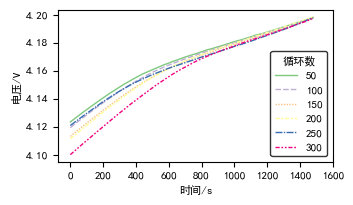

In [22]:
plt.figure(figsize=(9*cm, 5*cm))
cycle_1 = [50, 100 ,150, 200, 250, 300]
data=df_cc.iloc[cycle_1].T
data.columns = cycle_1
sns.lineplot(data=data, dashes=True, palette='Accent', linewidth=1)
plt.xticks(np.arange(0, 180, 20), np.arange(0, 180, 20)*10, fontsize=fontsize)
plt.yticks(fontsize=fontsize)
plt.xlabel('时间/s', fontsize=fontsize)
plt.ylabel('电压/V', fontsize=fontsize)
plt.rcParams.update({'font.size': fontsize})
plt.legend(title='循环数', edgecolor='black', fontsize=fontsize)
plt.savefig(r'D:\My_program\long\code\2-数据分析\CC-25-025_1-#1.png', dpi=600, bbox_inches='tight')

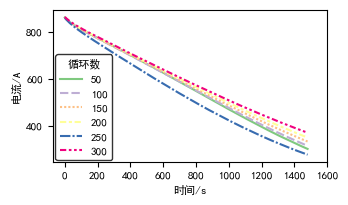

In [23]:
plt.figure(figsize=(9*cm, 5*cm))
cycle_1 = [50, 100 ,150, 200, 250, 300]
data=df_cv.iloc[cycle_1].T
data.columns = cycle_1
sns.lineplot(data=data, dashes=True, palette='Accent')
plt.xticks(np.arange(0, 180, 20), np.arange(0, 180, 20)*10, fontsize=fontsize)
plt.yticks(fontsize=fontsize)
plt.xlabel('时间/s', fontsize=fontsize)
plt.ylabel('电流/A', fontsize=fontsize)
plt.rcParams.update({'font.size': fontsize})
plt.legend(title='循环数', edgecolor='black', fontsize=fontsize, 
           loc = 'lower left', bbox_to_anchor=(-0.01, -0.025))
plt.savefig(r'D:\My_program\long\code\2-数据分析\CV-25-025_1-#1.png', dpi=600, bbox_inches='tight')

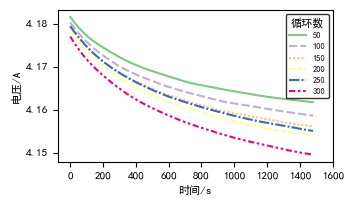

In [24]:
plt.figure(figsize=(9*cm, 5*cm))
cycle_1 = [50, 100 ,150, 200, 250, 300]
data=df_rest.iloc[cycle_1].T
data.columns = cycle_1
sns.lineplot(data=data, dashes=True, palette='Accent')
plt.xticks(np.arange(0, 180, 20), np.arange(0, 180, 20)*10, fontsize=fontsize)
plt.yticks(fontsize=fontsize)
plt.xlabel('时间/s', fontsize=fontsize)
plt.ylabel('电压/A', fontsize=fontsize)
plt.rcParams.update({'font.size': fontsize})
plt.legend(title='循环数', edgecolor='black', fontsize=fontsize-2, 
           loc = 'upper right')
plt.savefig(r'D:\My_program\long\code\2-数据分析\REST-25-025_1-#1.png', dpi=600, bbox_inches='tight')